# Figure 2 · Corrected conditional diffusion

**Question:** What does the diffusion model learn, and how does it generate a JWST-band image from NISP alone?

**Status:** vector schematic of the current full-run implementation. It shows
the corrected model, not the historical epsilon/clipped sampler. Drawing and
source hashing do not instantiate the network.

Training and inference must be visually distinct: JWST is a training target,
never an inference input.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
FIGSIZE = (9.0, 6.7)
source_paths = [ROOT / 'code/diffusion_corrected.py', ROOT / 'code/diffusion/model_sr3.py',
                ROOT / 'code/train_diffusion_full.py']
provenance = ROOT / 'runs/diffusion-full50-s20261016/provenance.json'
verified_sources(provenance, ['diffusion_corrected.py', 'diffusion/model_sr3.py', 'train_diffusion_full.py'])
print('Verified source hashes against the full diffusion run.')

Verified source hashes against the full diffusion run.


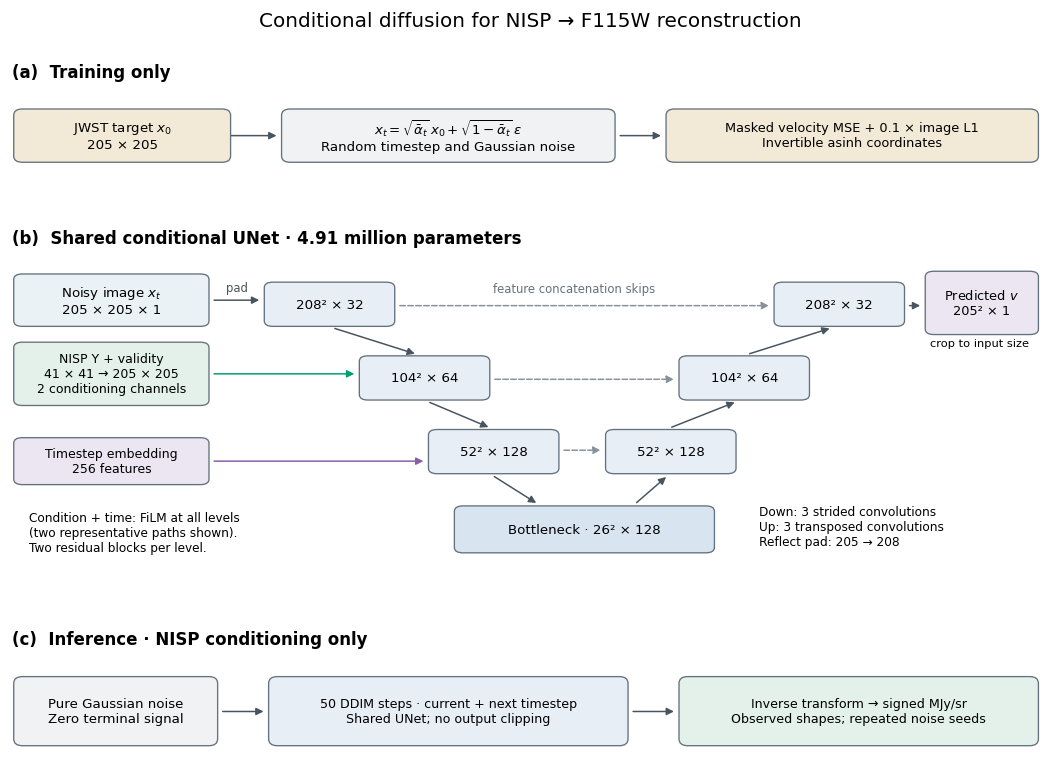

In [3]:
fig = plt.figure(figsize=FIGSIZE)
gs = fig.add_gridspec(3, 1, height_ratios=[1.1, 3.5, 1.35], hspace=.25, left=.02, right=.98, top=.91, bottom=.035)
top, net, bottom = [fig.add_subplot(gs[i]) for i in range(3)]
for ax in [top, net, bottom]: ax.axis('off')
top.set(xlim=(0, 12), ylim=(0, 1.8))
top.text(0, 1.65, '(a)  Training only', fontweight='semibold', fontsize=10)
box(top, .1, .35, 2.35, .7, 'JWST target $x_0$\n205 × 205', '#F2E9D7')
box(top, 3.2, .35, 3.7, .7, r'$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$'+'\nRandom timestep and Gaussian noise', '#F0F2F4')
box(top, 7.65, .35, 4.15, .7, 'Masked velocity MSE + 0.1 × image L1\nInvertible asinh coordinates', '#F2E9D7', 7.7)
arrow(top, (2.5, .7), (3.1, .7)); arrow(top, (7., .7), (7.55, .7))

net.set(xlim=(0, 12), ylim=(0, 6.5))
net.text(0, 6.25, '(b)  Shared conditional UNet · 4.91 million parameters', fontweight='semibold', fontsize=10)
box(net, .1, 4.8, 2.1, .8, 'Noisy image $x_t$\n205 × 205 × 1')
box(net, .1, 3.35, 2.1, 1., 'NISP Y + validity\n41 × 41 → 205 × 205\n2 conditioning channels', '#E3F1EA', 7.5)
box(net, .1, 1.9, 2.1, .7, 'Timestep embedding\n256 features', '#ECE6F3', 7.5)
for x, y, text in [(3., 4.8, '208² × 32'), (4.1, 3.45, '104² × 64'), (4.9, 2.1, '52² × 128'),
                   (8.9, 4.8, '208² × 32'), (7.8, 3.45, '104² × 64'), (6.95, 2.1, '52² × 128')]:
    box(net, x, y, 1.35, .65, text, '#E8EEF6', 8)
box(net, 5.2, .65, 2.85, .7, 'Bottleneck · 26² × 128', '#D9E4F1', 8)
arrow(net, (2.3, 5.2), (2.9, 5.2), label='pad')
arrow(net, (3.7, 4.7), (4.7, 4.2)); arrow(net, (4.8, 3.35), (5.55, 2.85))
arrow(net, (5.55, 2.), (6.1, 1.45)); arrow(net, (7.2, 1.45), (7.6, 2.))
arrow(net, (7.6, 2.85), (8.4, 3.35)); arrow(net, (8.5, 4.2), (9.5, 4.7))
for start, end in [((4.45, 5.1), (8.8, 5.1)), ((5.55, 3.75), (7.7, 3.75)), ((6.35, 2.45), (6.85, 2.45))]:
    if end[0] - start[0] > .1: arrow(net, start, end, color='#87929C', style='--')
net.text(6.5, 5.35, 'feature concatenation skips', ha='center', fontsize=7, color='#64727E')
box(net, 10.65, 4.65, 1.15, 1., 'Predicted $v$\n205² × 1', '#ECE6F3', 7.7)
arrow(net, (10.35, 5.1), (10.55, 5.1))
net.text(11.2, 4.35, 'crop to input size', ha='center', fontsize=6.8)
arrow(net, (2.3, 3.85), (4.0, 3.85), color=COLORS['direct5'])
arrow(net, (2.3, 2.25), (4.8, 2.25), color=COLORS['diffusion'])
net.text(.2, .55, 'Condition + time: FiLM at all levels\n(two representative paths shown).\nTwo residual blocks per level.', fontsize=7.3, va='bottom')
net.text(8.65, .65, 'Down: 3 strided convolutions\nUp: 3 transposed convolutions\nReflect pad: 205 → 208', fontsize=7.3, va='bottom')

bottom.set(xlim=(0, 12), ylim=(0, 2.))
bottom.text(0, 1.85, '(c)  Inference · NISP conditioning only', fontweight='semibold', fontsize=10)
box(bottom, .1, .45, 2.2, .85, 'Pure Gaussian noise\nZero terminal signal', '#F0F2F4')
box(bottom, 3.05, .45, 4., .85, '50 DDIM steps · current + next timestep\nShared UNet; no output clipping', '#E8EEF6', 7.6)
box(bottom, 7.8, .45, 4., .85, 'Inverse transform → signed MJy/sr\nObserved shapes; repeated noise seeds', '#E3F1EA', 7.6)
arrow(bottom, (2.4, .87), (2.95, .87)); arrow(bottom, (7.15, .87), (7.7, .87))
fig.suptitle('Conditional diffusion for NISP → F115W reconstruction', fontsize=12, y=.98)
plt.show()

In [4]:
paths = export(fig, f'fig02_diffusion_architecture_{VERSION}', '02_diffusion_architecture.ipynb',
               [*source_paths, provenance], dict(figsize=FIGSIZE, parameters=4910593,
                prediction='v', conditioning='NISP intensity and validity mask', inference_steps=50),
               status='implementation-verified vector schematic draft')

Exported: fig02_diffusion_architecture_v01.pdf, fig02_diffusion_architecture_v01.svg, fig02_diffusion_architecture_v01.png


## Working caption

Corrected conditional diffusion model. During training, noisy JWST targets and
NISP conditioning are used to learn velocity prediction with masked losses.
The UNet combines three spatial scales with timestep and input-condition
modulation. At inference the process starts from pure Gaussian noise and uses
NISP only; 50 DDIM transitions produce an image that is transformed back to
linear intensity before evaluation. Tensor labels show spatial dimensions and
feature channels; padding and cropping preserve the 205-pixel target grid.

## Review together

- Is the UNet detail useful at this scale, or should it be an inset?
- Add a small FiLM residual-block inset if space permits.
- Keep training-only JWST visually separated from the inference path.
- The two green/purple arrows denote modulation supplied throughout the UNet;
  two representative FiLM paths are drawn, with modulation at all levels.
- Skip links connect every corresponding encoder/decoder scale; simplify the
  middle layout only if all three links remain explicit.